# 01 · Exploration des données Brent–WTI

**Objectif** : charger et aligner Brent/WTI, examiner rendements, volatilité et spreads. On travaille sur les **futures front-month** (base tradable) ; le spot FRED sert de robustesse.

In [1]:
import sys, warnings
warnings.filterwarnings("ignore")
sys.path.insert(0, "..")
%matplotlib inline
import numpy as np, pandas as pd, matplotlib.pyplot as plt
plt.rcParams["figure.figsize"] = (11, 4)
plt.rcParams["axes.grid"] = True
from src import (data_loader as dl, features as ft, stats_tests as st,
                 hedge_ratio as hr, signal as sig, backtest as bt, metrics as mt,
                 curve as cv, regime as rg, pipeline as pl)
from src.config import StrategyConfig, MARKET_EVENTS, REGIME_SEGMENTS
def events(ax):
    for e in MARKET_EVENTS:
        ax.axvline(pd.Timestamp(e["date"]), color="gray", ls=":", lw=1, alpha=.6)


Matplotlib is building the font cache; this may take a moment.


futures (4761, 2) 2007-07-30 -> 2026-09-16


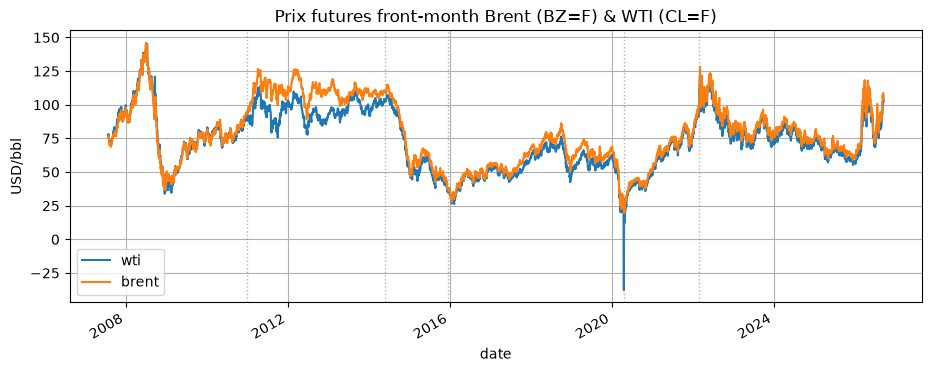

In [2]:
prices = dl.get_prices('futures')
fred = dl.get_prices('fred')
print('futures', prices.shape, prices.index.min().date(), '->', prices.index.max().date())
ax = prices.plot(title='Prix futures front-month Brent (BZ=F) & WTI (CL=F)')
events(ax); plt.ylabel('USD/bbl'); plt.show()

### Rendements & volatilité
Rendements **log** (additifs). Volatilité réalisée 21 j annualisée (×√252).

,n_obs,mean_daily,std_daily,ann_return,ann_vol,skew,kurtosis,min,max,ann_sharpe
wti,4758,0.0002,0.0275,0.0469,0.4361,0.0071,17.0291,-0.2822,0.3196,0.1075
brent,4758,0.0001,0.0240,0.0374,0.3808,-0.4770,8.6597,-0.2758,0.1908,0.0982


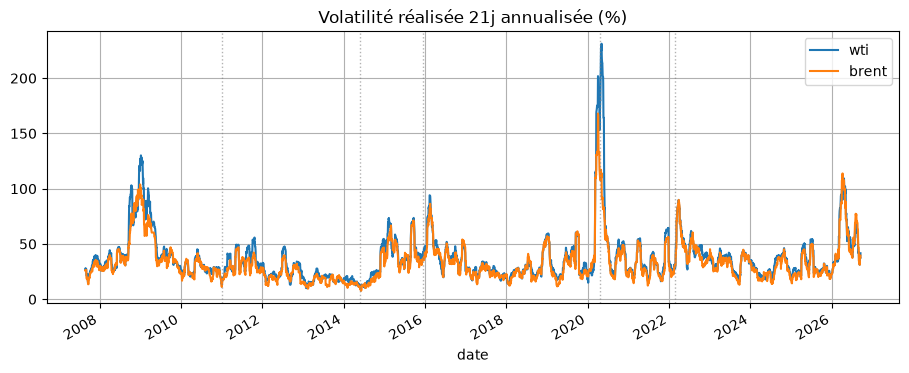

In [3]:
rets = ft.log_returns(prices).dropna()
display(ft.descriptive_stats(rets).round(4))
vol = pd.DataFrame({c: ft.rolling_vol(rets[c], 21) for c in rets})
ax = (vol*100).plot(title='Volatilité réalisée 21j annualisée (%)'); events(ax); plt.show()

### Spread Brent − WTI
Spread de prix et log-spread. On visualise la moyenne mobile et les bandes ±2σ.

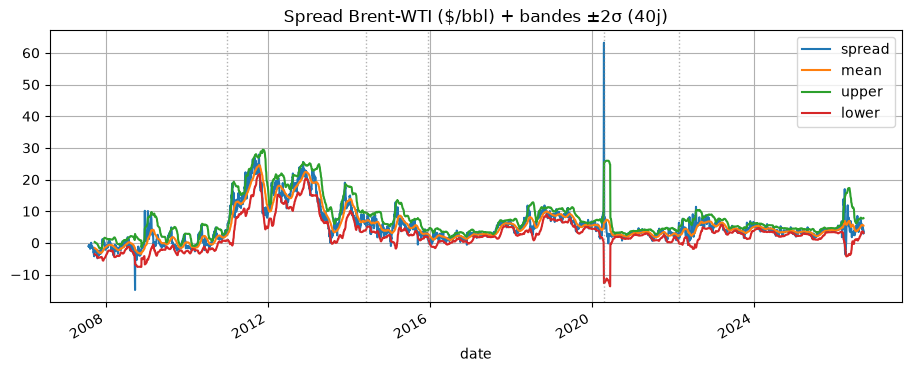

spread moyen 5.24, min -14.88, max 63.20


In [4]:
spread = ft.price_spread(prices)
band = ft.rolling_mean_band(spread, 40, n_std=2.0)
ax = band[['spread','mean','upper','lower']].plot(title='Spread Brent-WTI ($/bbl) + bandes ±2σ (40j)')
events(ax); plt.show()
print('spread moyen %.2f, min %.2f, max %.2f' % (spread.mean(), spread.min(), spread.max()))

**Lecture** : le spread oscille autour d'un niveau mais avec des épisodes de dérive persistante (2011-2015 discount WTI, 2020 choc COVID) — d'où la nécessité de tester la cointégration (notebook 02) avant de trader la mean-reversion.